# Lab 7: Python Physics Engine Prototype

**Name:** Alex Bebb  
**Course:** PHYS 311  
**Date:** October 18, 2026  

I will organize the physics from my earlier labs into a reusable
engine with separate components for bodies, forces, integration,
and simulation management.

I will validate the engine against familiar physical systems,
then use it to build an interacting multi-body scene. The checks
will include theoretical comparisons and the conservation laws
appropriate to each system.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Part A: Engine architecture

I will separate the engine into four main components:

- **Body:** stores each object's physical properties and current state.
- **Force:** calculates an interaction and adds its contribution to
  the affected bodies' force or torque accumulators.
- **Integrator:** updates positions, velocities, angles, and angular
  velocities using the selected numerical method.
- **World:** manages the bodies and interactions, advances the simulation,
  and records results.

Collision detection and resolution will be handled in a separate
module called by the world.

Each force calculation will begin by clearing the accumulators.
The force objects will then add their contributions, allowing several
forces to act on the same body without overwriting one another.

The integrator will use the accumulated forces and torques to advance
the motion. Euler-Cromer needs one force evaluation per step; Velocity
Verlet also needs forces evaluated at the updated positions.

This structure will let me change a scene's bodies, forces, or
integration method without rewriting the simulation loop.

### Relationships between engine components

```mermaid
classDiagram
    class World {
        bodies
        forces
        integrator
        history
        step(dt)
        run(dt, duration)
        compute_forces()
    }

    class Body {
        mass
        position
        velocity
        angle
        angular_velocity
        force
        torque
        clear_accumulators()
    }

    class Force {
        apply(world)
        potential_energy(world)
    }

    class Integrator {
        step(world, dt)
    }

    World "1" o-- "*" Body : stores
    World "1" o-- "*" Force : registers
    World "1" o-- "1" Integrator : selects
    Force --> Body : adds force and torque
    Integrator --> Body : updates motion
    Integrator --> World : requests force evaluation
```

The world will coordinate the simulation, while each component will
have a specific responsibility. The integrator will request force
evaluations through the world so it can evaluate forces when its
numerical method requires them.

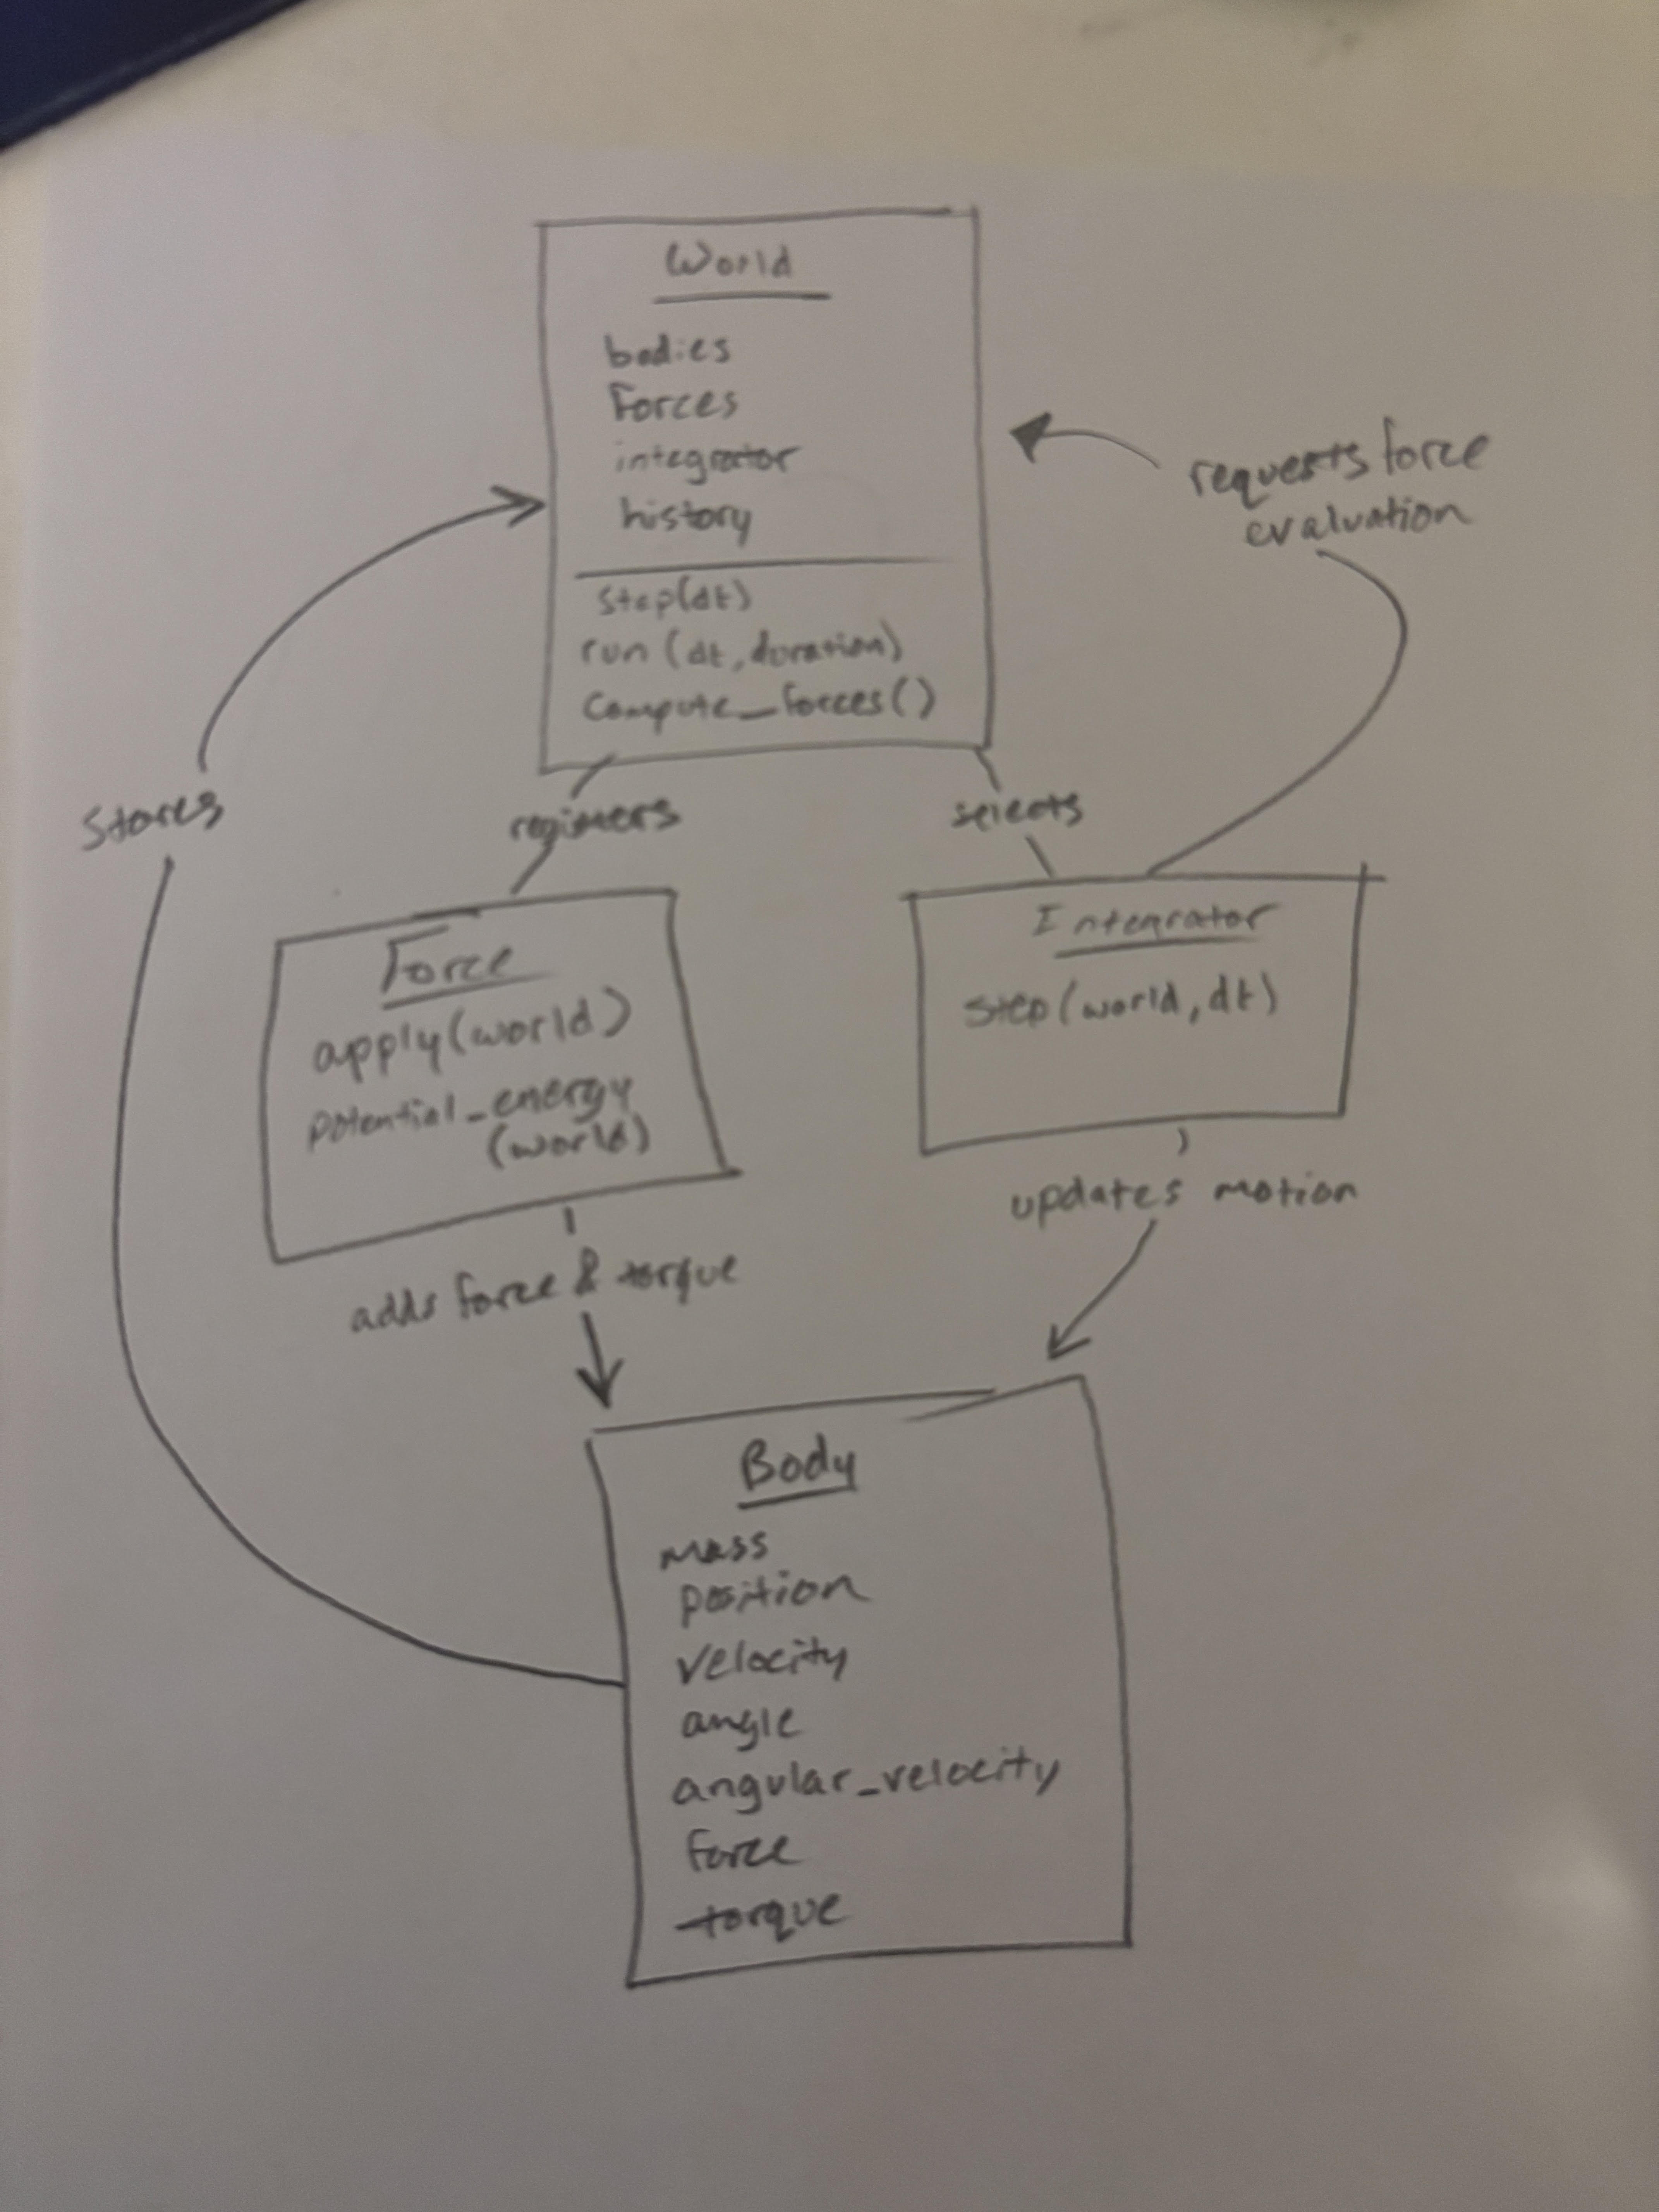

### Representing a body

I will use the Body class to store each object's mass, position,
velocity, and optional rotational state. Each body will also have
force and torque accumulators, which will be cleared before each
force evaluation.

The class will calculate kinetic energy, linear momentum, and angular
momentum from its current state. It will not advance its own motion;
that will be the integrator's responsibility.

I will first create a test body and compare these calculations with
values that can be checked by hand.

In [2]:
from lab07_engine.body import Body

test_body = Body(
    mass=2.0,
    position=[1.0, 2.0],
    velocity=[3.0, -1.0],
    radius=0.5,
    moment_of_inertia=0.25,
    angular_velocity=4.0,
    name="test body"
)

print(f"Name: {test_body.name}")
print(f"Mass: {test_body.mass:.2f} kg")
print(f"Position: {test_body.position} m")
print(f"Velocity: {test_body.velocity} m/s")
print(f"Kinetic energy: {test_body.kinetic_energy():.2f} J")
print(f"Linear momentum: {test_body.momentum()} kg m/s")
print(
    f"Angular momentum about origin: "
    f"{test_body.angular_momentum():.2f} kg m^2/s"
)

Name: test body
Mass: 2.00 kg
Position: [1. 2.] m
Velocity: [ 3. -1.] m/s
Kinetic energy: 12.00 J
Linear momentum: [ 6. -2.] kg m/s
Angular momentum about origin: -13.00 kg m^2/s


### Defining reusable forces

I will implement uniform gravity, a spring between two bodies, and
pairwise Newtonian gravity in the forces module.

Each force class will provide an apply(world) method that adds its
contribution to the bodies' force accumulators. It will also provide
a potential_energy(world) method for energy accounting.

Spring and gravitational pair interactions will apply equal and
opposite forces to their endpoints. Each gravitational pair will
be counted once when calculating forces and potential energy.

I will first check that the force classes import correctly and retain
their parameters. Their effects on motion will be tested after the
world and integrators are implemented.

In [3]:
from lab07_engine.forces import Gravity, Spring, NewtonGravity

test_gravity = Gravity(g=9.81)
test_spring = Spring(index_a=0, index_b=1, k=4.0, rest_length=0.0)
test_newton_gravity = NewtonGravity(G=1.0)

print(f"Uniform gravitational acceleration: {test_gravity.g:.2f} m/s^2")
print(f"Spring constant: {test_spring.k:.2f} N/m")
print(f"Spring rest length: {test_spring.rest_length:.2f} m")
print(
    f"Spring connects body indices: "
    f"{test_spring.index_a} and {test_spring.index_b}"
)
print(f"Newtonian gravity constant: {test_newton_gravity.G:.2f}")
print(f"Gravitational softening: {test_newton_gravity.softening:.2f}")

Uniform gravitational acceleration: 9.81 m/s^2
Spring constant: 4.00 N/m
Spring rest length: 0.00 m
Spring connects body indices: 0 and 1
Newtonian gravity constant: 1.00
Gravitational softening: 0.00


### Swappable integration methods

I will implement Euler-Cromer and Velocity Verlet with the same
step(world, dt) interface. This will let the world use either method
without changing the scene's bodies or forces.

Euler-Cromer will update velocity before position. Velocity Verlet
will use a half-step velocity update, a full position update, and
a second half-step velocity update using the new forces.

For interacting bodies, all positions will be updated before the
second force evaluation. The Verlet implementation will be used
with position-dependent forces.

Both methods will also support rotational motion for bodies with
a specified, positive moment of inertia. Fixed bodies will be
skipped during motion updates.

In [4]:
from lab07_engine.integrators import EulerCromer, VelocityVerlet

test_euler_cromer = EulerCromer()
test_verlet = VelocityVerlet()

print(f"First available integrator: {test_euler_cromer.name}")
print(f"Second available integrator: {test_verlet.name}")

First available integrator: Euler-Cromer
Second available integrator: Velocity Verlet


### Collision detection and response

I will treat contacting bodies as smooth circles. The collision
response will apply an impulse along the line joining their centers,
with no tangential frictional impulse or change in spin.

Each pair will be checked once. Overlapping bodies will be separated,
but a collision impulse will only be applied if they are approaching.
Stationary box walls will reverse the velocity component normal to
the wall, scaled by the coefficient of restitution.

I will first test a head-on elastic collision between two equal
masses with opposite velocities. They should exchange velocities,
while total linear momentum and kinetic energy remain unchanged.

The position correction is an approximation to contact handling.
Scenes with forces and collisions will require time-step checks.

In [5]:
from lab07_engine.collisions import resolve_pair, CircleCollisions, BoxWalls

# Start with slight overlap to exercise the contact correction.
collision_a = Body(
    mass=1.0,
    position=[0.0, 0.0],
    velocity=[1.0, 0.0],
    radius=0.5,
    name="A"
)

collision_b = Body(
    mass=1.0,
    position=[0.9, 0.0],
    velocity=[-1.0, 0.0],
    radius=0.5,
    name="B"
)

momentum_before = collision_a.momentum() + collision_b.momentum()
energy_before = collision_a.kinetic_energy() + collision_b.kinetic_energy()

collision_occurred = resolve_pair(
    collision_a, collision_b, restitution=1.0
)

momentum_after = collision_a.momentum() + collision_b.momentum()
energy_after = collision_a.kinetic_energy() + collision_b.kinetic_energy()

print(f"Collision impulse applied: {collision_occurred}")
print(f"Body A final velocity: {collision_a.velocity} m/s")
print(f"Body B final velocity: {collision_b.velocity} m/s")
print(
    f"Final center separation: "
    f"{np.linalg.norm(collision_b.position - collision_a.position):.3f} m"
)
print(f"Initial kinetic energy: {energy_before:.3f} J")
print(f"Final kinetic energy: {energy_after:.3f} J")
print(
    "Momentum conserved:",
    np.allclose(momentum_before, momentum_after)
)
print("Kinetic energy conserved:", np.isclose(energy_before, energy_after))

Collision impulse applied: True
Body A final velocity: [-1.  0.] m/s
Body B final velocity: [1. 0.] m/s
Final center separation: 1.000 m
Initial kinetic energy: 1.000 J
Final kinetic energy: 1.000 J
Momentum conserved: True
Kinetic energy conserved: True


### Managing the simulation with World

The World class will store the bodies, forces, collision handlers,
and selected integrator. Its run method will perform the time loop,
so individual experiments will only need to construct a scene and
request a run.

The integrator will request force evaluations through the world.
Each evaluation will clear the accumulators before adding all
registered force contributions.

The world will record the initial state and each subsequent state,
including positions, velocities, rotational variables, total
mechanical energy, linear momentum, and angular momentum.

I will first check that multiple forces add correctly, repeated force
evaluations do not accumulate old contributions, and the recorded
history preserves the initial state.

In [6]:
from lab07_engine.world import World

test_world = World(integrator=EulerCromer())

falling_body = test_world.add_body(
    Body(
        mass=2.0,
        position=[0.0, 1.0],
        velocity=[0.0, 0.0],
        name="falling body"
    )
)

# Split gravity into two contributions to test force accumulation.
test_world.add_force(Gravity(g=3.0))
test_world.add_force(Gravity(g=6.81))

test_world.compute_forces()
first_force = falling_body.force.copy()

test_world.compute_forces()
second_force = falling_body.force.copy()

print(f"Combined force: {first_force} N")
print(
    "Force contributions add correctly:",
    np.allclose(first_force, [0.0, -19.62])
)
print(
    "Repeated evaluation gives the same force:",
    np.allclose(first_force, second_force)
)

test_history = test_world.run(dt=0.01, duration=0.1)

print(f"\nFinal time: {test_world.time:.3f} s")
print(f"Stored time points: {len(test_history['time'])}")
print(f"Position history shape: {test_history['position'].shape}")
print(f"Recorded initial position: {test_history['position'][0, 0]} m")
print(f"Final position: {falling_body.position} m")
print(f"Final velocity: {falling_body.velocity} m/s")

Combined force: [  0.   -19.62] N
Force contributions add correctly: True
Repeated evaluation gives the same force: True

Final time: 0.100 s
Stored time points: 11
Position history shape: (11, 1, 2)
Recorded initial position: [0. 1.] m
Final position: [0.       0.946045] m
Final velocity: [ 0.    -0.981] m/s


### Checking the recorded trajectory

For a body released from rest in uniform gravity, Euler-Cromer gives

$$
v_{y,n}=-gn\Delta t,
$$

$$
y_n=y_0-\frac12g(\Delta t)^2n(n+1).
$$

I will compare the recorded motion with these discrete predictions.
This will check that the world and integrator work together correctly.

The exact continuous solution has position

$$
y(t)=y_0-\frac12gt^2.
$$

Euler-Cromer's position differs from that solution at finite time
steps. Agreement with the discrete prediction verifies the
implementation; comparison with the continuous solution will assess
its numerical accuracy in Part B.

In [7]:
step_numbers = np.arange(len(test_history["time"]))

expected_y = (
    1.0 - 0.5 * 9.81 * 0.01**2 * step_numbers * (step_numbers + 1)
)
expected_vy = -9.81 * 0.01 * step_numbers

recorded_y = test_history["position"][:, 0, 1]
recorded_vy = test_history["velocity"][:, 0, 1]

print(
    "Recorded positions match Euler-Cromer prediction:",
    np.allclose(recorded_y, expected_y)
)
print(
    "Recorded velocities match prediction:",
    np.allclose(recorded_vy, expected_vy)
)
print(
    "Initial position preserved:",
    np.allclose(test_history["position"][0, 0], [0.0, 1.0])
)

Recorded positions match Euler-Cromer prediction: True
Recorded velocities match prediction: True
Initial position preserved: True


## Part B: Validation against earlier labs

I will test the engine by reproducing projectile motion, a harmonic
oscillator, and an orbit. Each simulation will run through World.run,
without a separate time-stepping loop in the notebook.

I will compare the results with known analytical predictions and
check the conservation laws appropriate to each system.

### Projectile motion

I will launch a 1 kg projectile from the origin at 30 m/s and
50 degrees above horizontal. Only uniform gravity will act on it.

The analytical trajectory is

$$
x(t)=v_{0x}t,
$$

$$
y(t)=v_{0y}t-\frac12gt^2.
$$

I will use Euler-Cromer and compare the numerical trajectory with
these predictions. Mechanical energy should be conserved in the
physical model, although Euler-Cromer introduces numerical drift.
Horizontal momentum should remain constant because there is no
horizontal force.

Simulation duration: 4.000 s
Stored time points: 401
Maximum vertical position error: 0.196200 m
Initial mechanical energy: 450.000000 J
Final mechanical energy: 448.075278 J
Maximum absolute energy deviation: 1.924722 J
Maximum horizontal momentum deviation: 0.000e+00 kg m/s


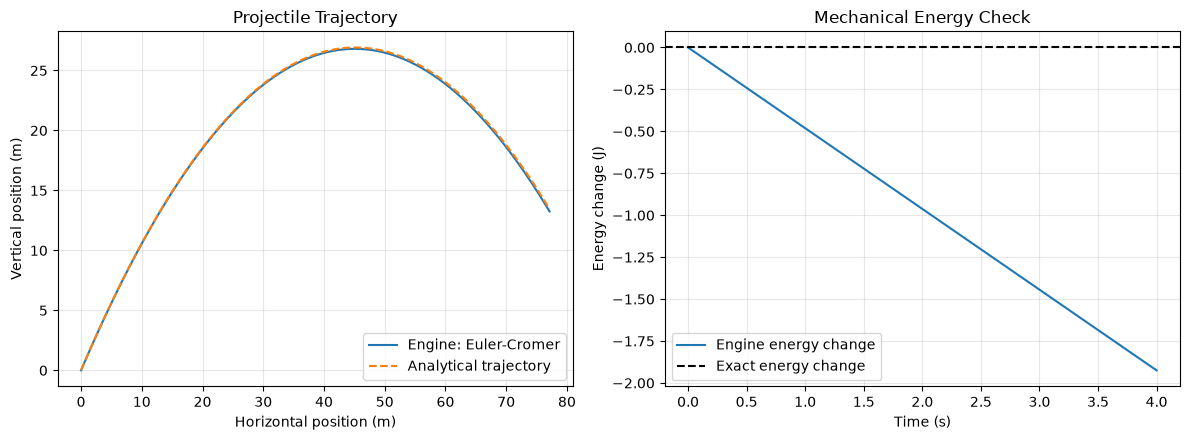

In [8]:
def run_projectile(dt):
    """Construct and run a projectile scene using the engine."""
    speed = 30.0  # m/s
    launch_angle = np.radians(50.0)

    world = World(integrator=EulerCromer())

    world.add_body(
        Body(
            mass=1.0,
            position=[0.0, 0.0],
            velocity=[
                speed * np.cos(launch_angle),
                speed * np.sin(launch_angle)
            ],
            name="projectile"
        )
    )

    world.add_force(Gravity(g=9.81))

    return world.run(dt=dt, duration=4.0)


projectile_dt = 0.01
projectile_history = run_projectile(projectile_dt)

t_projectile = projectile_history["time"]
r_projectile = projectile_history["position"][:, 0, :]
E_projectile = projectile_history["energy"]
p_projectile = projectile_history["momentum"]

vx_initial = 30.0 * np.cos(np.radians(50.0))
vy_initial = 30.0 * np.sin(np.radians(50.0))

x_exact = vx_initial * t_projectile
y_exact = vy_initial * t_projectile - 0.5 * 9.81 * t_projectile**2

max_y_error = np.max(np.abs(r_projectile[:, 1] - y_exact))
max_energy_error = np.max(np.abs(E_projectile - E_projectile[0]))
max_px_error = np.max(np.abs(p_projectile[:, 0] - p_projectile[0, 0]))

print(f"Simulation duration: {t_projectile[-1]:.3f} s")
print(f"Stored time points: {len(t_projectile)}")
print(f"Maximum vertical position error: {max_y_error:.6f} m")
print(f"Initial mechanical energy: {E_projectile[0]:.6f} J")
print(f"Final mechanical energy: {E_projectile[-1]:.6f} J")
print(f"Maximum absolute energy deviation: {max_energy_error:.6f} J")
print(f"Maximum horizontal momentum deviation: {max_px_error:.3e} kg m/s")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    r_projectile[:, 0], r_projectile[:, 1],
    label="Engine: Euler-Cromer"
)
axes[0].plot(
    x_exact, y_exact,
    linestyle="--", label="Analytical trajectory"
)
axes[0].set_xlabel("Horizontal position (m)")
axes[0].set_ylabel("Vertical position (m)")
axes[0].set_title("Projectile Trajectory")
axes[0].legend()

axes[1].plot(
    t_projectile, E_projectile - E_projectile[0],
    label="Engine energy change"
)
axes[1].axhline(
    0.0, color="black", linestyle="--",
    label="Exact energy change"
)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Energy change (J)")
axes[1].set_title("Mechanical Energy Check")
axes[1].legend()

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Projectile time-step refinement

I will repeat the simulation with half the time step and compare
the maximum vertical position error and energy deviation.

For constant gravity, Euler-Cromer's vertical position error at a
fixed time is proportional to the time step:

$$
y_{\mathrm{EC}}(t)-y_{\mathrm{exact}}(t)
=-\frac12gt\Delta t.
$$

Its mechanical energy change is

$$
E_{\mathrm{EC}}(t)-E_0
=-\frac12mg^2t\Delta t.
$$

Halving the time step should therefore halve both errors. This will
check that the engine reproduces the numerical behavior of the
method, as well as approaching the analytical trajectory.

In [9]:
projectile_refined = run_projectile(projectile_dt / 2)

t_refined = projectile_refined["time"]
y_refined = projectile_refined["position"][:, 0, 1]
E_refined = projectile_refined["energy"]

y_exact_refined = vy_initial * t_refined - 0.5 * 9.81 * t_refined**2

refined_y_error = np.max(np.abs(y_refined - y_exact_refined))
refined_energy_error = np.max(np.abs(E_refined - E_refined[0]))

print(
    f"{'Time step (s)':>15} {'Max y error (m)':>18}"
    f" {'Max energy error (J)':>23}"
)
print(
    f"{projectile_dt:>15.6f} {max_y_error:>18.6f}"
    f" {max_energy_error:>23.6f}"
)
print(
    f"{projectile_dt / 2:>15.6f} {refined_y_error:>18.6f}"
    f" {refined_energy_error:>23.6f}"
)

print(f"\nPosition error reduction factor: {max_y_error / refined_y_error:.6f}")
print(f"Energy error reduction factor: {max_energy_error / refined_energy_error:.6f}")

  Time step (s)    Max y error (m)    Max energy error (J)
       0.010000           0.196200                1.924722
       0.005000           0.098100                0.962361

Position error reduction factor: 2.000000
Energy error reduction factor: 2.000000


### Projectile interpretation

The engine trajectory closely followed the analytical prediction.
Horizontal momentum remained constant, while mechanical energy
decreased slightly because of numerical error in Euler-Cromer.

Halving the time step halved both the maximum vertical position error
and the maximum energy deviation. This matched the expected behavior
of the method for constant gravity.

The results showed that the engine reproduced the projectile model
and its numerical error behavior using the reusable world and
integrator, without a separate time-stepping loop in the notebook.

### Harmonic oscillator

I will connect a moving mass to a fixed anchor with a spring of
zero rest length. The motion will remain along the x-axis.

With mass $m=1$ kg and spring constant $k=1$ N/m, the natural angular
frequency and period are

$$
\Omega=\sqrt{\frac{k}{m}}=1\ \mathrm{rad/s},
$$

$$
T=\frac{2\pi}{\Omega}=2\pi\ \mathrm{s}.
$$

For release from rest at $x_0=1$ m, the analytical solution is

$$
x(t)=x_0\cos(\Omega t),
$$

$$
v_x(t)=-x_0\Omega\sin(\Omega t).
$$

I will compare the engine's displacement and phase-space trajectory
with these predictions and track total mechanical energy. Linear
momentum of the moving mass is not conserved because the anchored
spring exerts an external force on it.

Predicted period: 6.283185 s
Stored time points: 4001
Initial mechanical energy: 0.500000 J
Maximum position error: 0.005164 m
Maximum energy deviation: 0.002513 J
Maximum relative energy deviation: 0.5025%


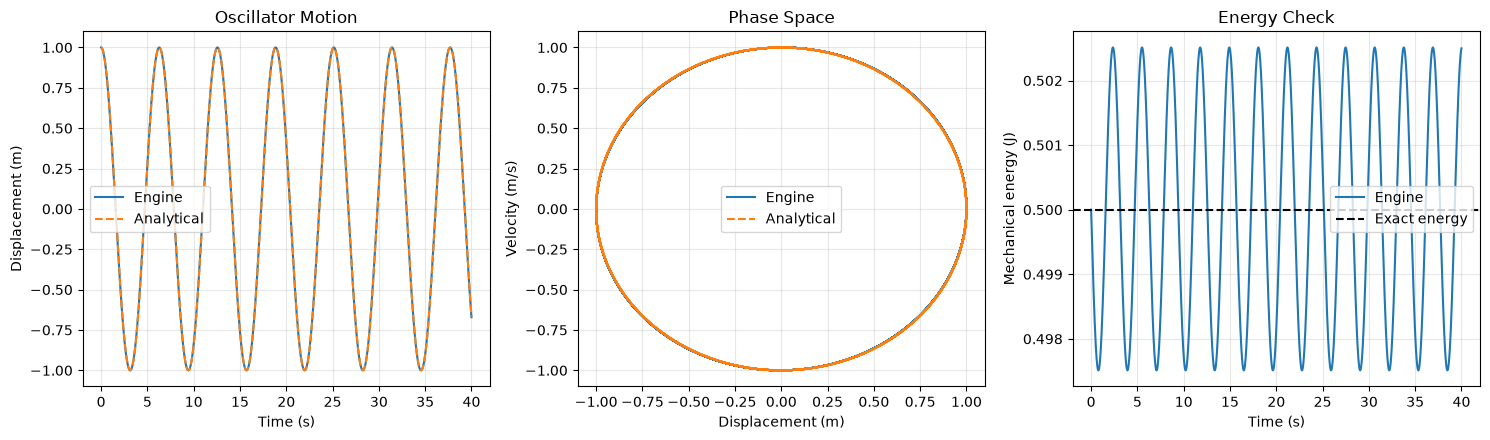

In [10]:
def run_oscillator(dt):
    """Construct an anchored spring oscillator and run it through the engine."""
    world = World(integrator=EulerCromer())

    # Body 0 is the fixed anchor.
    world.add_body(
        Body(
            mass=1.0,
            position=[0.0, 0.0],
            velocity=[0.0, 0.0],
            fixed=True,
            name="anchor"
        )
    )

    # Body 1 is the moving mass.
    world.add_body(
        Body(
            mass=1.0,
            position=[1.0, 0.0],
            velocity=[0.0, 0.0],
            name="oscillating mass"
        )
    )

    world.add_force(
        Spring(index_a=0, index_b=1, k=1.0, rest_length=0.0)
    )

    return world.run(dt=dt, duration=40.0)


oscillator_dt = 0.01
oscillator_history = run_oscillator(oscillator_dt)

t_oscillator = oscillator_history["time"]
x_oscillator = oscillator_history["position"][:, 1, 0]
vx_oscillator = oscillator_history["velocity"][:, 1, 0]
E_oscillator = oscillator_history["energy"]

Omega_oscillator = np.sqrt(1.0 / 1.0)
T_oscillator_exact = 2 * np.pi / Omega_oscillator

x_oscillator_exact = np.cos(Omega_oscillator * t_oscillator)
vx_oscillator_exact = (
    -Omega_oscillator * np.sin(Omega_oscillator * t_oscillator)
)

oscillator_position_error = np.max(
    np.abs(x_oscillator - x_oscillator_exact)
)
oscillator_energy_error = np.max(
    np.abs(E_oscillator - E_oscillator[0])
)

print(f"Predicted period: {T_oscillator_exact:.6f} s")
print(f"Stored time points: {len(t_oscillator)}")
print(f"Initial mechanical energy: {E_oscillator[0]:.6f} J")
print(f"Maximum position error: {oscillator_position_error:.6f} m")
print(f"Maximum energy deviation: {oscillator_energy_error:.6f} J")
print(
    f"Maximum relative energy deviation: "
    f"{100 * oscillator_energy_error / E_oscillator[0]:.4f}%"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(t_oscillator, x_oscillator, label="Engine")
axes[0].plot(
    t_oscillator, x_oscillator_exact,
    linestyle="--", label="Analytical"
)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Displacement (m)")
axes[0].set_title("Oscillator Motion")
axes[0].legend()

axes[1].plot(x_oscillator, vx_oscillator, label="Engine")
axes[1].plot(
    x_oscillator_exact, vx_oscillator_exact,
    linestyle="--", label="Analytical"
)
axes[1].set_xlabel("Displacement (m)")
axes[1].set_ylabel("Velocity (m/s)")
axes[1].set_title("Phase Space")
axes[1].legend()

axes[2].plot(t_oscillator, E_oscillator, label="Engine")
axes[2].axhline(
    E_oscillator[0], color="black", linestyle="--",
    label="Exact energy"
)
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Mechanical energy (J)")
axes[2].set_title("Energy Check")
axes[2].legend()

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Oscillator period and time-step refinement

I will measure the period using successive crossings of equilibrium
in the negative direction. Linear interpolation between stored
positions will estimate each crossing time.

I will repeat the simulation with half the time step and compare
the period, maximum position error, and maximum energy deviation.

The period should approach the analytical value of $2\pi$ seconds,
while the position and energy errors should decrease. For this
oscillator, Euler-Cromer's period can be much more accurate than
its point-by-point position, so I will check both quantities.

In [11]:
def measure_period(times, positions):
    """Estimate the period from successive downward zero crossings."""
    crossing_times = []

    for i in range(len(positions) - 1):
        if positions[i] > 0.0 and positions[i + 1] <= 0.0:
            fraction = positions[i] / (positions[i] - positions[i + 1])

            crossing_time = (
                times[i] + fraction * (times[i + 1] - times[i])
            )
            crossing_times.append(crossing_time)

    if len(crossing_times) < 2:
        raise ValueError("More simulation time is needed to measure a period.")

    return np.mean(np.diff(crossing_times))


# Measure the original run's period.
oscillator_period = measure_period(t_oscillator, x_oscillator)

# Repeat from the same initial conditions with half the time step.
oscillator_refined = run_oscillator(oscillator_dt / 2)

t_osc_refined = oscillator_refined["time"]
x_osc_refined = oscillator_refined["position"][:, 1, 0]
E_osc_refined = oscillator_refined["energy"]

oscillator_period_refined = measure_period(t_osc_refined, x_osc_refined)

oscillator_position_error_refined = np.max(
    np.abs(x_osc_refined - np.cos(Omega_oscillator * t_osc_refined))
)
oscillator_energy_error_refined = np.max(
    np.abs(E_osc_refined - E_osc_refined[0])
)

print(f"Analytical period: {T_oscillator_exact:.8f} s")

print(
    f"\n{'dt (s)':>10} {'Measured T (s)':>17}"
    f" {'Max x error (m)':>18} {'Max energy error (J)':>23}"
)
print(
    f"{oscillator_dt:>10.5f} {oscillator_period:>17.8f}"
    f" {oscillator_position_error:>18.8f}"
    f" {oscillator_energy_error:>23.8f}"
)
print(
    f"{oscillator_dt / 2:>10.5f} {oscillator_period_refined:>17.8f}"
    f" {oscillator_position_error_refined:>18.8f}"
    f" {oscillator_energy_error_refined:>23.8f}"
)

print(
    f"\nPosition error reduction factor: "
    f"{oscillator_position_error / oscillator_position_error_refined:.4f}"
)
print(
    f"Energy error reduction factor: "
    f"{oscillator_energy_error / oscillator_energy_error_refined:.4f}"
)

Analytical period: 6.28318531 s

    dt (s)    Measured T (s)    Max x error (m)    Max energy error (J)
   0.01000        6.28315913         0.00516369              0.00251256
   0.00500        6.28317876         0.00254091              0.00125313

Position error reduction factor: 2.0322
Energy error reduction factor: 2.0050


### Oscillator interpretation

The engine reproduced the analytical oscillation closely, and the
phase-space trajectory remained near the predicted ellipse.
The measured period agreed closely with $2\pi$ seconds.

The mechanical energy oscillated around its initial value with a
small bounded error. Halving the time step reduced the maximum
position error and energy deviation by approximately a factor of
two, while also improving the measured period.

These results showed that the spring force, fixed anchor, integrator,
and recording system worked together as expected. The same engine
that ran the projectile handled this system by changing the scene
setup rather than the time-stepping loop.

### Orbital motion

I will use normalized units with $G=1$ and a fixed central mass
$M=1$. A small orbiting body will start at $(1,0)$ with velocity
$(0,0.8)$, matching the orbital initial conditions used in Lab 5.

I will use Velocity Verlet and unsoftened Newtonian gravity.
The initial specific mechanical energy is

$$
\varepsilon=\frac{v_0^2}{2}-\frac{GM}{r_0}=-0.68.
$$

The predicted semi-major axis is

$$
a=-\frac{GM}{2\varepsilon}.
$$

The specific angular momentum is $h=0.8$, giving eccentricity

$$
e=\sqrt{1+\frac{2\varepsilon h^2}{(GM)^2}}=0.36.
$$

The body starts at apoapsis. With periapsis along the negative x-axis,
the predicted ellipse can be parameterized as

$$
x=a\cos(u)+ae,
$$

$$
y=a\sqrt{1-e^2}\sin(u).
$$

I will overlay the engine trajectory on this ellipse and check energy
and angular momentum. Total linear momentum is not expected to be
conserved in this fixed-center model because the central body is
held stationary by an external constraint.

Predicted semi-major axis: 0.735294
Measured semi-major axis: 0.735295
Predicted eccentricity: 0.360000
Measured eccentricity: 0.359999
Measured periapsis distance: 0.470589
Measured apoapsis distance: 1.000000
Predicted orbital period: 3.961608
Maximum relative energy deviation: 2.132e-06
Maximum relative angular momentum deviation: 1.323e-14


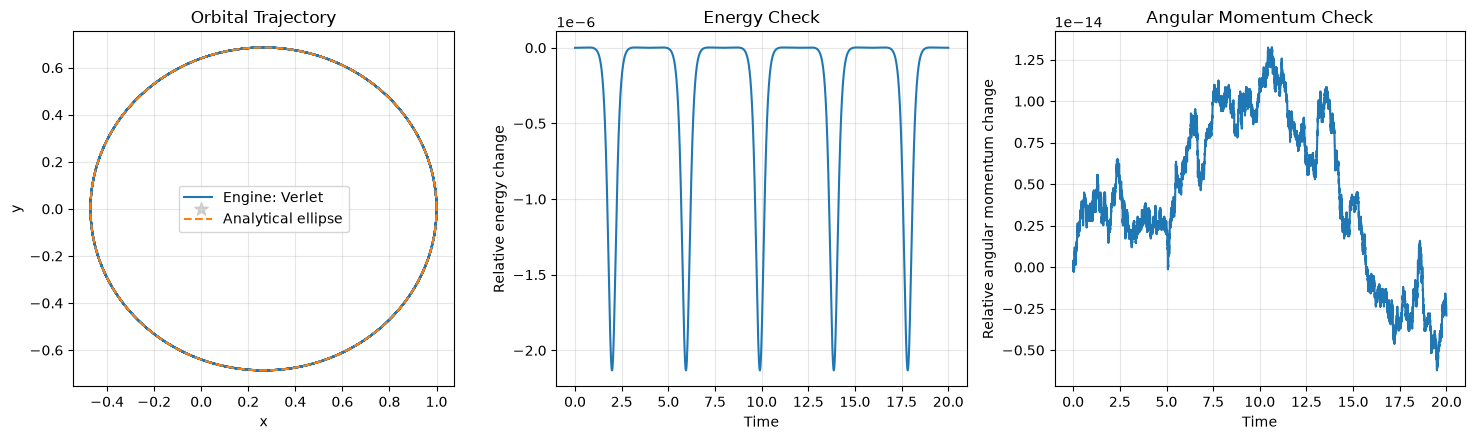

In [12]:
def run_orbit(dt, integrator=None):
    """Construct the fixed-center orbit and run it through the engine."""
    if integrator is None:
        integrator = VelocityVerlet()

    world = World(integrator=integrator)

    world.add_body(
        Body(
            mass=1.0,
            position=[0.0, 0.0],
            velocity=[0.0, 0.0],
            fixed=True,
            name="central mass"
        )
    )

    world.add_body(
        Body(
            mass=1e-6,
            position=[1.0, 0.0],
            velocity=[0.0, 0.8],
            name="orbiting body"
        )
    )

    world.add_force(NewtonGravity(G=1.0, softening=0.0))

    return world.run(dt=dt, duration=20.0)


orbit_dt = 0.001
orbit_history = run_orbit(orbit_dt)

t_orbit = orbit_history["time"]
r_orbit = orbit_history["position"][:, 1, :]
E_orbit = orbit_history["energy"]
L_orbit = orbit_history["angular_momentum"]

orbital_radius = np.linalg.norm(r_orbit, axis=1)

specific_energy_initial = 0.5 * 0.8**2 - 1.0
specific_angular_momentum = 0.8

a_predicted = -1.0 / (2 * specific_energy_initial)
e_predicted = np.sqrt(
    1 + 2 * specific_energy_initial * specific_angular_momentum**2
)
T_orbit_predicted = 2 * np.pi * a_predicted**1.5

periapsis_measured = np.min(orbital_radius)
apoapsis_measured = np.max(orbital_radius)
a_measured = 0.5 * (periapsis_measured + apoapsis_measured)
e_measured = (
    (apoapsis_measured - periapsis_measured)
    / (apoapsis_measured + periapsis_measured)
)

orbit_energy_error = np.max(np.abs(E_orbit - E_orbit[0])) / abs(E_orbit[0])
orbit_L_error = np.max(np.abs(L_orbit - L_orbit[0])) / abs(L_orbit[0])

print(f"Predicted semi-major axis: {a_predicted:.6f}")
print(f"Measured semi-major axis: {a_measured:.6f}")
print(f"Predicted eccentricity: {e_predicted:.6f}")
print(f"Measured eccentricity: {e_measured:.6f}")
print(f"Measured periapsis distance: {periapsis_measured:.6f}")
print(f"Measured apoapsis distance: {apoapsis_measured:.6f}")
print(f"Predicted orbital period: {T_orbit_predicted:.6f}")
print(f"Maximum relative energy deviation: {orbit_energy_error:.3e}")
print(f"Maximum relative angular momentum deviation: {orbit_L_error:.3e}")

# Parameterize the analytical ellipse; u is not the simulation time.
u_ellipse = np.linspace(0.0, 2 * np.pi, 600)
ellipse_x = a_predicted * np.cos(u_ellipse) + a_predicted * e_predicted
ellipse_y = (
    a_predicted * np.sqrt(1 - e_predicted**2) * np.sin(u_ellipse)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(r_orbit[:, 0], r_orbit[:, 1], label="Engine: Verlet")
axes[0].plot(
    ellipse_x, ellipse_y,
    linestyle="--", label="Analytical ellipse"
)
axes[0].scatter([0.0], [0.0], color="black", marker="*", s=100)
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Orbital Trajectory")
axes[0].set_aspect("equal")
axes[0].legend()

axes[1].plot(t_orbit, (E_orbit - E_orbit[0]) / abs(E_orbit[0]))
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Relative energy change")
axes[1].set_title("Energy Check")

axes[2].plot(t_orbit, (L_orbit - L_orbit[0]) / abs(L_orbit[0]))
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Relative angular momentum change")
axes[2].set_title("Angular Momentum Check")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Orbital period and time-step refinement

The analytical orbital period follows Kepler's third law:

$$
T=2\pi\sqrt{\frac{a^3}{GM}}.
$$

I will measure the period using successive downward crossings of
the x-axis, applying the existing zero-crossing function to the
orbiting body's y-coordinate.

I will repeat the orbit with half the time step and compare the
measured periods and maximum relative energy deviations. For this
smooth orbit, Velocity Verlet's second-order accuracy should reduce
the energy error by approximately a factor of four.

In [13]:
orbit_period_measured = measure_period(t_orbit, r_orbit[:, 1])

orbit_refined = run_orbit(orbit_dt / 2)

t_orbit_refined = orbit_refined["time"]
r_orbit_refined = orbit_refined["position"][:, 1, :]
E_orbit_refined = orbit_refined["energy"]

orbit_period_refined = measure_period(
    t_orbit_refined, r_orbit_refined[:, 1]
)

orbit_energy_error_refined = (
    np.max(np.abs(E_orbit_refined - E_orbit_refined[0]))
    / abs(E_orbit_refined[0])
)

print(f"Predicted orbital period: {T_orbit_predicted:.8f}")

print(
    f"\n{'dt':>10} {'Measured period':>19}"
    f" {'Period error (%)':>19} {'Max relative dE':>19}"
)

for dt, period, energy_error in [
    (orbit_dt, orbit_period_measured, orbit_energy_error),
    (orbit_dt / 2, orbit_period_refined, orbit_energy_error_refined)
]:
    period_error_percent = (
        100 * abs(period - T_orbit_predicted) / T_orbit_predicted
    )

    print(
        f"{dt:>10.6f} {period:>19.8f}"
        f" {period_error_percent:>19.6f} {energy_error:>19.3e}"
    )

print(
    f"\nEnergy error reduction factor: "
    f"{orbit_energy_error / orbit_energy_error_refined:.4f}"
)

Predicted orbital period: 3.96160805

        dt     Measured period    Period error (%)     Max relative dE
  0.001000          3.96160936            0.000033           2.132e-06
  0.000500          3.96160838            0.000008           5.330e-07

Energy error reduction factor: 4.0000


### Orbit interpretation and Part B summary

The engine's orbit closely followed the analytical ellipse. The
measured semi-major axis, eccentricity, and orbital period agreed
with the predictions for the initial conditions.

Angular momentum remained constant to within rounding error, while
mechanical energy showed a small bounded numerical error. Halving
the time step reduced the maximum relative energy deviation by
approximately a factor of four, consistent with Velocity Verlet's
second-order accuracy for this smooth problem.

The engine reproduced projectile motion, a harmonic oscillator,
and an orbit using different scene setups with the same simulation
framework. No experiment required its own time-stepping loop in
the notebook. These comparisons checked both the physical results
and the expected numerical behavior of the integration methods.

## Part C: A hanging chain of interacting masses

I will model four moving masses connected by springs, with the top
spring attached to a fixed anchor. Uniform gravity will act on each
moving mass.

The masses will begin slightly displaced sideways from a vertical
line, causing the chain to swing and stretch. Each interior mass
will experience forces from two neighboring springs as well as
gravity.

I will neglect damping, air resistance, and collisions. The bodies
will behave as point masses connected by ideal springs.

Total mechanical energy will include the moving masses' kinetic
energy, gravitational potential energy, and the potential energy
stored in all four springs. It should remain approximately constant,
with numerical error decreasing as the time step is reduced.

Linear momentum is not conserved because gravity and the fixed
support exert external forces on the moving system. Angular momentum
about the anchor is also not generally conserved because gravity
can exert a torque about it.

In [14]:
def run_spring_chain(dt):
    """Build and simulate four masses suspended from a fixed anchor."""
    world = World(integrator=VelocityVerlet())

    # Body 0 is the fixed anchor.
    world.add_body(
        Body(
            mass=1.0,
            position=[0.0, 4.0],
            velocity=[0.0, 0.0],
            fixed=True,
            name="anchor"
        )
    )

    initial_positions = [
        [0.30, 3.40],
        [-0.15, 2.80],
        [0.20, 2.20],
        [-0.10, 1.60]
    ]

    # Bodies 1–4 are the moving masses.
    for number, position in enumerate(initial_positions, start=1):
        world.add_body(
            Body(
                mass=0.5,
                position=position,
                velocity=[0.0, 0.0],
                name=f"mass {number}"
            )
        )

    world.add_force(Gravity(g=9.81))

    # Connect 0–1, 1–2, 2–3, and 3–4.
    for index in range(4):
        world.add_force(
            Spring(
                index_a=index,
                index_b=index + 1,
                k=40.0,
                rest_length=0.6
            )
        )

    return world.run(dt=dt, duration=10.0)


chain_dt = 0.001
chain_history = run_spring_chain(chain_dt)

t_chain = chain_history["time"]
r_chain = chain_history["position"]
E_chain = chain_history["energy"]

chain_energy_deviation = np.max(np.abs(E_chain - E_chain[0]))
chain_relative_energy_deviation = chain_energy_deviation / abs(E_chain[0])

anchor_displacement = np.linalg.norm(
    r_chain[:, 0, :] - r_chain[0, 0, :],
    axis=1
)

print(f"Moving masses: {r_chain.shape[1] - 1}")
print(f"Total bodies, including anchor: {r_chain.shape[1]}")
print(f"Simulation duration: {t_chain[-1]:.3f} s")
print(f"Stored time points: {len(t_chain)}")
print(f"Initial mechanical energy: {E_chain[0]:.6f} J")
print(f"Final mechanical energy: {E_chain[-1]:.6f} J")
print(f"Maximum absolute energy deviation: {chain_energy_deviation:.3e} J")
print(
    f"Maximum relative energy deviation: "
    f"{chain_relative_energy_deviation:.3e}"
)
print(f"Maximum anchor displacement: {np.max(anchor_displacement):.3e} m")

Moving masses: 4
Total bodies, including anchor: 5
Simulation duration: 10.000 s
Stored time points: 10001
Initial mechanical energy: 49.879688 J
Final mechanical energy: 49.879671 J
Maximum absolute energy deviation: 5.864e-05 J
Maximum relative energy deviation: 1.176e-06
Maximum anchor displacement: 0.000e+00 m


### Time-step refinement

I will repeat the chain simulation with half the time step, using
the same initial conditions.

I will compare the maximum energy deviations and the positions at
matching times. For this smooth system, Velocity Verlet should
reduce the energy error by approximately a factor of four when
the time step is halved.

Agreement between the trajectories will provide an additional check:
a small energy error alone does not guarantee accurate positions.

In [15]:
chain_refined = run_spring_chain(chain_dt / 2)

E_chain_refined = chain_refined["energy"]
r_chain_refined = chain_refined["position"]

chain_energy_deviation_refined = np.max(
    np.abs(E_chain_refined - E_chain_refined[0])
)

# Every second refined sample corresponds to an original sample.
matching_refined_positions = r_chain_refined[::2]

position_differences = np.linalg.norm(
    matching_refined_positions[:, 1:, :] - r_chain[:, 1:, :],
    axis=2
)

max_chain_position_difference = np.max(position_differences)

print(
    f"{'Time step (s)':>15} {'Max energy deviation (J)':>27}"
)
print(f"{chain_dt:>15.6f} {chain_energy_deviation:>27.6e}")
print(
    f"{chain_dt / 2:>15.6f}"
    f" {chain_energy_deviation_refined:>27.6e}"
)

print(
    f"\nEnergy error reduction factor: "
    f"{chain_energy_deviation / chain_energy_deviation_refined:.4f}"
)
print(
    f"Maximum position difference at matching times: "
    f"{max_chain_position_difference:.6e} m"
)
print(
    "Recorded times align:",
    np.allclose(chain_refined["time"][::2], t_chain)
)

  Time step (s)    Max energy deviation (J)
       0.001000                5.863919e-05
       0.000500                1.466122e-05

Energy error reduction factor: 3.9996
Maximum position difference at matching times: 6.745913e-05 m
Recorded times align: True


### Energy partition in the chain

I will calculate the energy contributions from the recorded positions
and velocities:

$$
K=\sum_{i=1}^{4}\frac12m_i|\mathbf{v}_i|^2,
$$

$$
U_g=\sum_{i=1}^{4}m_i g y_i,
$$

$$
U_s=\sum_{\text{springs}}\frac12k(\ell-\ell_0)^2.
$$

The fixed anchor contributes no kinetic energy. Its gravitational
potential energy is omitted as a constant reference contribution.

I will plot the three contributions and their sum. Individual
energies can vary as the chain moves, while their sum should remain
approximately constant.

I will also compare this reconstructed total with the energy recorded
by the engine to check that the bookkeeping agrees.

Initial kinetic energy: 0.000000 J
Initial gravitational potential energy: 49.050000 J
Initial spring potential energy: 0.829688 J
Maximum difference from engine energy: 2.132e-14 J
Energy bookkeeping agrees: True


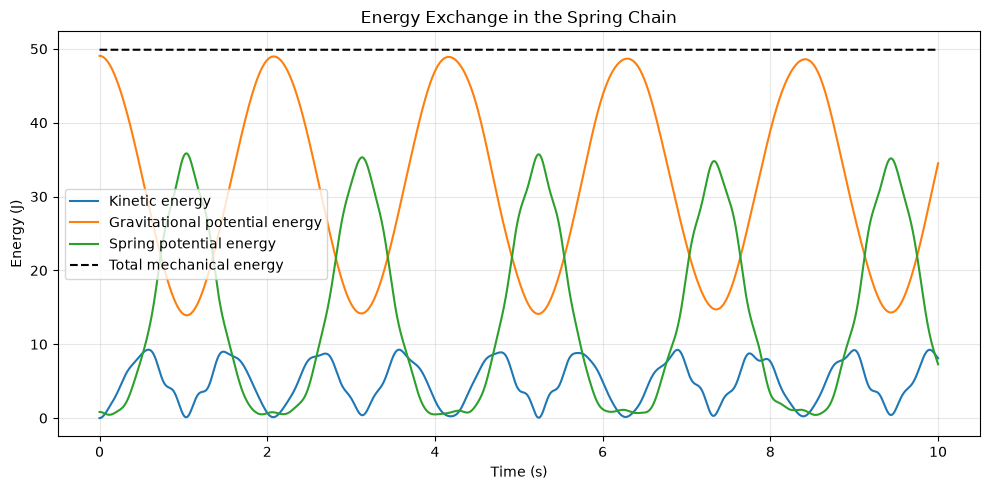

In [16]:
chain_mass = 0.5
chain_spring_k = 40.0
chain_rest_length = 0.6
chain_g = 9.81

moving_velocities = chain_history["velocity"][:, 1:, :]
moving_positions = r_chain[:, 1:, :]

# Sum over coordinates to obtain each body's squared speed.
speed_squared = np.sum(moving_velocities**2, axis=2)

# Sum over the four moving bodies.
K_chain = np.sum(0.5 * chain_mass * speed_squared, axis=1)
Ug_chain = np.sum(
    chain_mass * chain_g * moving_positions[:, :, 1],
    axis=1
)

# Each spring joins adjacent bodies, including the anchor.
spring_vectors = r_chain[:, 1:, :] - r_chain[:, :-1, :]
spring_lengths = np.linalg.norm(spring_vectors, axis=2)

Us_chain = np.sum(
    0.5 * chain_spring_k * (spring_lengths - chain_rest_length)**2,
    axis=1
)

E_chain_reconstructed = K_chain + Ug_chain + Us_chain

bookkeeping_difference = np.max(
    np.abs(E_chain_reconstructed - E_chain)
)

print(f"Initial kinetic energy: {K_chain[0]:.6f} J")
print(f"Initial gravitational potential energy: {Ug_chain[0]:.6f} J")
print(f"Initial spring potential energy: {Us_chain[0]:.6f} J")
print(
    f"Maximum difference from engine energy: "
    f"{bookkeeping_difference:.3e} J"
)
print(
    "Energy bookkeeping agrees:",
    np.allclose(E_chain_reconstructed, E_chain)
)

plt.figure(figsize=(10, 5))

plt.plot(t_chain, K_chain, label="Kinetic energy")
plt.plot(t_chain, Ug_chain, label="Gravitational potential energy")
plt.plot(t_chain, Us_chain, label="Spring potential energy")
plt.plot(
    t_chain, E_chain_reconstructed,
    color="black", linestyle="--",
    label="Total mechanical energy"
)

plt.xlabel("Time (s)")
plt.ylabel("Energy (J)")
plt.title("Energy Exchange in the Spring Chain")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Part C interpretation

The four masses exhibited coupled swinging and stretching motion.
Their kinetic, gravitational potential, and spring potential energies
changed during the motion, while total mechanical energy remained
nearly constant.

Halving the time step reduced the maximum energy deviation by
approximately a factor of four, consistent with Velocity Verlet's
second-order accuracy. Comparing positions at matching times also
provided a check on the trajectories, rather than relying on energy
conservation alone.

The energy reconstructed from the recorded positions and velocities
agreed with the engine's energy calculation. The anchor remained
stationary throughout the simulation.

This scene combined uniform gravity and several spring interactions
without changing the engine. Adding bodies and connecting them with
forces was enough to construct a more complicated system from the
same components used in Part B.

### Visualizing the chain and checking energy

I will plot each moving mass's trajectory and show the spring
connections at the beginning and end of the simulation.

I will also plot horizontal position against time for each mass
and the total mechanical energy change. The motions can be more
complicated than a single sinusoid because the masses are coupled
and can exchange energy through the springs.

The energy plot will help distinguish physical redistribution of
energy within the chain from numerical changes in the total.

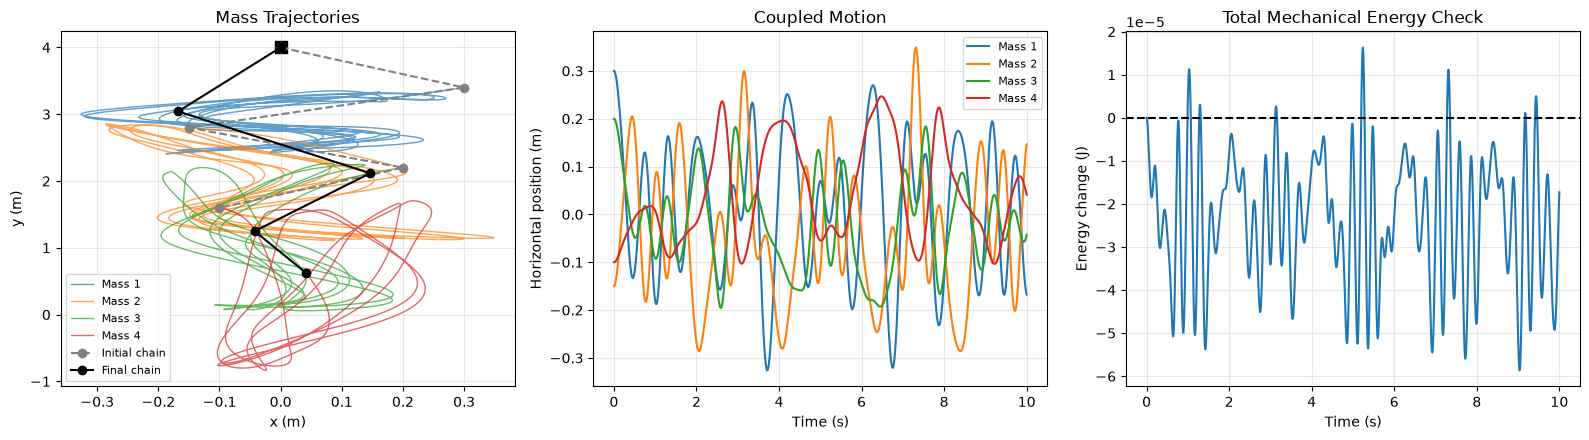

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

for body_index, color in enumerate(colors, start=1):
    axes[0].plot(
        r_chain[:, body_index, 0],
        r_chain[:, body_index, 1],
        color=color,
        alpha=0.7,
        linewidth=1.0,
        label=f"Mass {body_index}"
    )

    axes[1].plot(
        t_chain,
        r_chain[:, body_index, 0],
        color=color,
        label=f"Mass {body_index}"
    )

# Connect the anchor and moving masses in their chain order.
axes[0].plot(
    r_chain[0, :, 0], r_chain[0, :, 1],
    "o--", color="gray", label="Initial chain"
)
axes[0].plot(
    r_chain[-1, :, 0], r_chain[-1, :, 1],
    "o-", color="black", label="Final chain"
)
axes[0].scatter(
    [r_chain[0, 0, 0]], [r_chain[0, 0, 1]],
    marker="s", color="black", s=70
)

axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
axes[0].set_title("Mass Trajectories")
axes[0].set_aspect("auto")
axes[0].legend(fontsize=8)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Horizontal position (m)")
axes[1].set_title("Coupled Motion")
axes[1].legend(fontsize=8)

axes[2].plot(t_chain, E_chain - E_chain[0])
axes[2].axhline(0.0, color="black", linestyle="--")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Energy change (J)")
axes[2].set_title("Total Mechanical Energy Check")
axes[2].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Bonus: Swapping integrators

I will compare Euler-Cromer and Velocity Verlet using the same
orbital scene, initial conditions, duration, and time step.

The run_orbit function accepts an integrator object, so changing
the method requires changing only the integrator argument. The
bodies, force calculation, recording system, and simulation loop
will remain the same.

I will use a time step of 0.01 to make the differences more visible
than in the earlier validation. I will compare the trajectories,
maximum relative energy deviations, and angular momentum changes.

Both methods should maintain angular momentum closely for this
central-force problem, but Velocity Verlet should produce a smaller
energy error and a more accurate orbital trajectory.

In [18]:
bonus_dt = 0.01

# Same scene and time step; only the selected integrator changes.
bonus_ec = run_orbit(bonus_dt, integrator=EulerCromer())
bonus_verlet = run_orbit(bonus_dt, integrator=VelocityVerlet())

bonus_results = {
    "Euler-Cromer": bonus_ec,
    "Velocity Verlet": bonus_verlet
}

bonus_energy_errors = {}

print(f"Time step: {bonus_dt:.3f}")
print(f"Simulation duration: {bonus_ec['time'][-1]:.3f}")

print(
    f"\n{'Method':<18} {'Max relative dE':>19}"
    f" {'Max relative dL':>19}"
)

for name, history in bonus_results.items():
    energy = history["energy"]
    angular_momentum = history["angular_momentum"]

    energy_error = (
        np.max(np.abs(energy - energy[0])) / abs(energy[0])
    )
    momentum_error = (
        np.max(np.abs(angular_momentum - angular_momentum[0]))
        / abs(angular_momentum[0])
    )

    bonus_energy_errors[name] = energy_error

    print(
        f"{name:<18} {energy_error:>19.6e}"
        f" {momentum_error:>19.6e}"
    )

improvement_factor = (
    bonus_energy_errors["Euler-Cromer"]
    / bonus_energy_errors["Velocity Verlet"]
)

print(f"\nEnergy-error improvement factor: {improvement_factor:.2f}")

Time step: 0.010
Simulation duration: 20.000

Method                 Max relative dE     Max relative dL
Euler-Cromer              9.903277e-03        3.044025e-15
Velocity Verlet           2.130170e-04        3.970467e-15

Energy-error improvement factor: 46.49


### Comparing orbital stability and accuracy

I will overlay both numerical trajectories on the analytical ellipse
and compare their relative energy changes over time.

I will also plot the radius as a function of time. This will help
reveal differences in the timing and size of the radial oscillations
that may be difficult to see in the trajectory overlay.

A stable-looking orbit does not necessarily mean an accurate orbit.
The energy diagnostics will provide a quantitative comparison
alongside the plots.

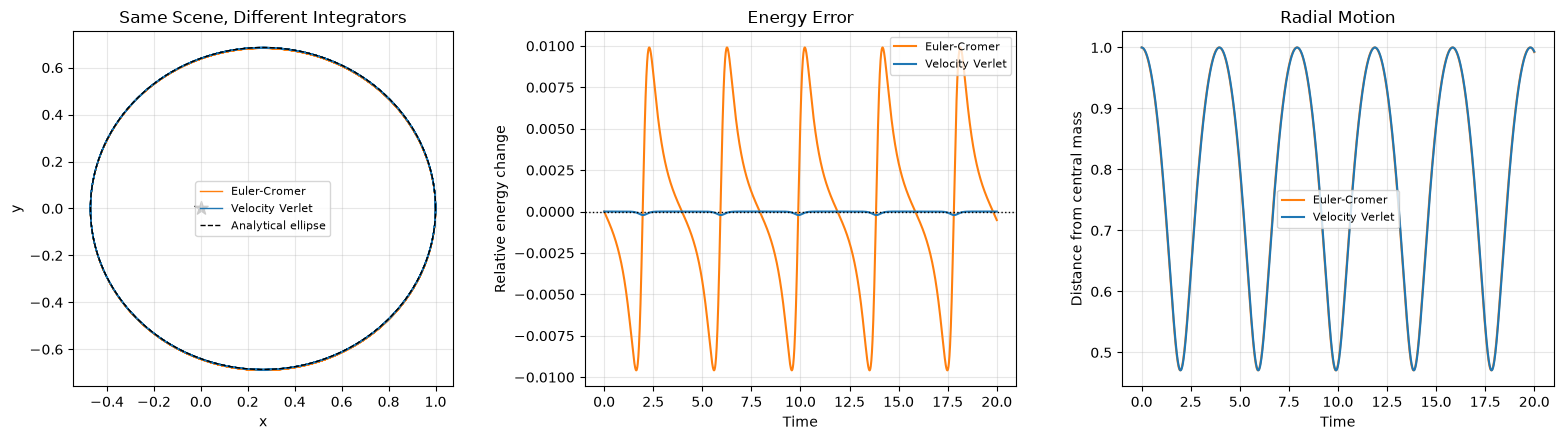

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

method_colors = {
    "Euler-Cromer": "tab:orange",
    "Velocity Verlet": "tab:blue"
}

for name, history in bonus_results.items():
    times = history["time"]
    positions = history["position"][:, 1, :]
    energy = history["energy"]
    radius = np.linalg.norm(positions, axis=1)

    color = method_colors[name]

    axes[0].plot(
        positions[:, 0], positions[:, 1],
        color=color, linewidth=1.0, label=name
    )

    axes[1].plot(
        times, (energy - energy[0]) / abs(energy[0]),
        color=color, label=name
    )

    axes[2].plot(
        times, radius,
        color=color, label=name
    )

axes[0].plot(
    ellipse_x, ellipse_y,
    color="black", linestyle="--",
    linewidth=1.0, label="Analytical ellipse"
)
axes[0].scatter([0.0], [0.0], marker="*", color="black", s=100)
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Same Scene, Different Integrators")
axes[0].set_aspect("equal")

axes[1].axhline(0.0, color="black", linestyle=":", linewidth=1.0)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Relative energy change")
axes[1].set_title("Energy Error")

axes[2].set_xlabel("Time")
axes[2].set_ylabel("Distance from central mass")
axes[2].set_title("Radial Motion")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Bonus interpretation

Velocity Verlet produced a smaller maximum relative energy deviation
than Euler-Cromer at the same time step. Both methods maintained
angular momentum closely, but the smaller energy error supported
using Verlet for accurate orbital simulations.

Euler-Cromer still produced a bounded orbit in this test. The
comparison showed that remaining stable and accurately following
the intended orbit are different requirements.

Switching methods required changing only the integrator argument
in the scene's function call. No changes were needed to the bodies,
gravitational force, world, or recording code. This demonstrated
the benefit of separating the numerical method from the physical
scene.